# First-Order Differential Equations

Notes with worked examples: analytical methods (separable, linear, exact), direction fields, numerical methods (Euler, Heun, RK4), and applications.

**Contents**
1. Definitions and initial value problems
2. Direction fields
3. Separable equations
4. Linear equations (integrating factor)
5. Exact equations
6. Numerical methods: Euler, Heun (improved Euler), Runge–Kutta 4 — derivations and worked examples
7. Error, order and efficiency (including Richardson error estimates)
8. Stability and stiff equations
9. Numerical methods in practice: adaptive step size, choosing a method, pitfalls
10. Applications: Newton's law of cooling, logistic growth
11. An equation with no elementary solution
12. Summary
13. Exercises

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (7, 4.5)
plt.rcParams["axes.grid"] = True
np.set_printoptions(precision=6, suppress=True)

## 1. Definitions

A **first-order ordinary differential equation (ODE)** relates an unknown function $y(x)$ to its first derivative:

$$\frac{dy}{dx} = f(x, y).$$

An **initial value problem (IVP)** adds a starting condition:

$$\frac{dy}{dx} = f(x, y), \qquad y(x_0) = y_0.$$

* A **general solution** contains an arbitrary constant $C$ (a one-parameter family of curves).
* A **particular solution** is the member of that family that satisfies the initial condition.

**Existence and uniqueness (Picard's theorem).** If $f$ and $\partial f/\partial y$ are continuous in a rectangle containing $(x_0, y_0)$, the IVP has exactly one solution on some interval around $x_0$.

*Example where uniqueness fails:* $y' = 3y^{2/3}$, $y(0)=0$. Both $y = 0$ and $y = x^3$ are solutions, because $\partial f/\partial y = 2y^{-1/3}$ is not continuous at $y = 0$.

## 2. Direction fields

At every point $(x, y)$ the equation gives the slope $f(x,y)$ of the solution curve passing through it. Drawing short line segments with these slopes produces a **direction (slope) field**. Solution curves follow the arrows.

Below is the field for $y' = x - y$, with a few solution curves. The exact solution is $y = x - 1 + Ce^{-x}$, so every curve approaches the line $y = x - 1$.

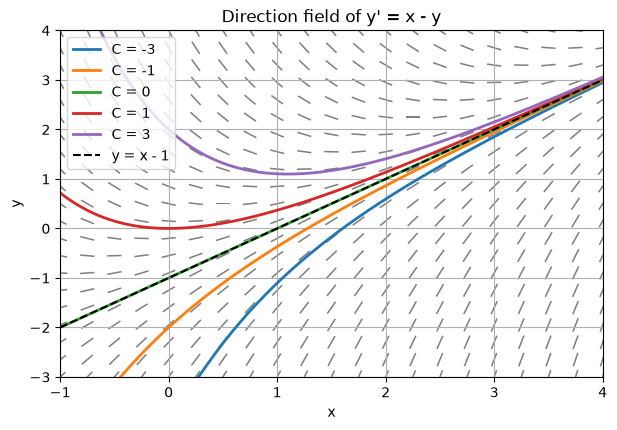

In [2]:
def direction_field(f, xlim, ylim, n=21, ax=None):
    # Draw normalised slope segments of y' = f(x, y).
    ax = ax or plt.gca()
    X, Y = np.meshgrid(np.linspace(*xlim, n), np.linspace(*ylim, n))
    S = f(X, Y)
    L = np.sqrt(1 + S**2)
    ax.quiver(X, Y, 1 / L, S / L, angles="xy", color="gray",
              headwidth=0, headlength=0, headaxislength=0, pivot="middle")
    ax.set_xlim(xlim); ax.set_ylim(ylim)
    ax.set_xlabel("x"); ax.set_ylabel("y")
    return ax

f = lambda x, y: x - y
ax = direction_field(f, (-1, 4), (-3, 4))
x = np.linspace(-1, 4, 200)
for C in [-3, -1, 0, 1, 3]:
    ax.plot(x, x - 1 + C * np.exp(-x), lw=2, label=f"C = {C}")
ax.plot(x, x - 1, "k--", label="y = x - 1")
ax.set_title("Direction field of y' = x - y")
ax.legend(loc="upper left");

## 3. Separable equations

An equation is **separable** if it can be written as

$$\frac{dy}{dx} = g(x)\,h(y).$$

**Method:** separate the variables and integrate both sides:

$$\int \frac{dy}{h(y)} = \int g(x)\,dx + C.$$

### Worked example 3.1

Solve $\dfrac{dy}{dx} = xy$, $y(0) = 1$.

1. Separate: $\dfrac{dy}{y} = x\,dx$.
2. Integrate: $\ln|y| = \dfrac{x^2}{2} + C$.
3. Solve for $y$: $y = Ae^{x^2/2}$.
4. Apply $y(0)=1$: $A = 1$, so $\boxed{y = e^{x^2/2}}$.

Check: $y' = x e^{x^2/2} = xy$. ✓  Numerically, $y(1) = e^{0.5} \approx 1.648721$.

### Worked example 3.2

Solve $\dfrac{dy}{dx} = \dfrac{x^2}{1 + y}$, $y(0) = 0$.

1. $(1 + y)\,dy = x^2\,dx$
2. $y + \dfrac{y^2}{2} = \dfrac{x^3}{3} + C$, and $y(0)=0$ gives $C = 0$.
3. Solve the quadratic $y^2 + 2y - \tfrac{2}{3}x^3 = 0$ and take the root through the origin:
   $\boxed{y = -1 + \sqrt{1 + \tfrac{2}{3}x^3}}$.

At $x = 1$: $y = -1 + \sqrt{5/3} \approx 0.290994$.

Example 3.1  y(1) = 1.6487212707001282
Example 3.2  y(1) = 0.2909944487358056


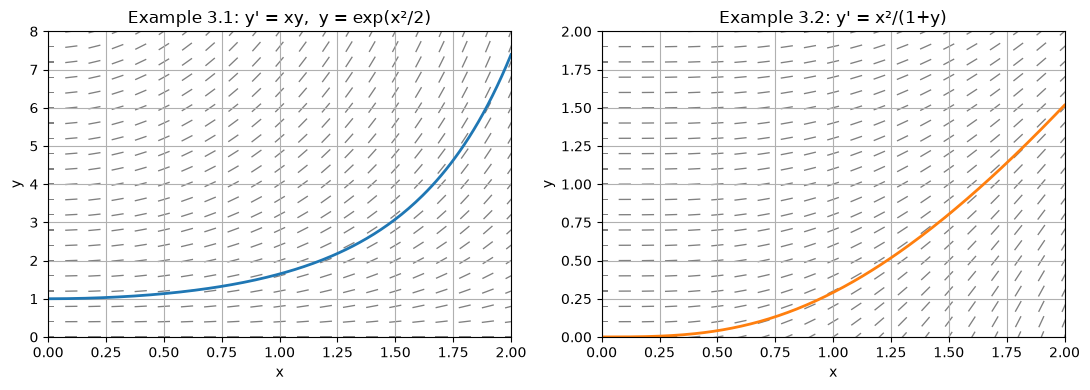

In [3]:
x = np.linspace(0, 2, 200)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

direction_field(lambda x, y: x * y, (0, 2), (0, 8), ax=axes[0])
axes[0].plot(x, np.exp(x**2 / 2), "C0", lw=2)
axes[0].set_title("Example 3.1: y' = xy,  y = exp(x²/2)")

direction_field(lambda x, y: x**2 / (1 + y), (0, 2), (0, 2), ax=axes[1])
axes[1].plot(x, -1 + np.sqrt(1 + 2 * x**3 / 3), "C1", lw=2)
axes[1].set_title("Example 3.2: y' = x²/(1+y)")
plt.tight_layout()

print("Example 3.1  y(1) =", np.exp(0.5))
print("Example 3.2  y(1) =", -1 + np.sqrt(5 / 3))

## 4. Linear first-order equations

Standard form:

$$\frac{dy}{dx} + P(x)\,y = Q(x).$$

**Method (integrating factor):**

1. Compute $\mu(x) = e^{\int P(x)\,dx}$.
2. Multiply through: $\mu y' + \mu P y = \mu Q$. The left side is exactly $(\mu y)'$.
3. Integrate: $\mu(x)\,y = \int \mu(x) Q(x)\,dx + C$.
4. Divide by $\mu$.

### Worked example 4.1

Solve $y' + y = x$, $y(0) = 1$.

1. $P = 1$, so $\mu = e^{x}$.
2. $(e^{x}y)' = x e^{x}$.
3. Integrate by parts: $e^{x}y = (x - 1)e^{x} + C$.
4. $y = x - 1 + Ce^{-x}$. From $y(0) = 1$: $-1 + C = 1$, so $C = 2$.

$$\boxed{y = x - 1 + 2e^{-x}}$$

### Worked example 4.2

Solve $x y' + 2y = 4x^2$, $y(1) = 2$, for $x > 0$.

1. Standard form: $y' + \dfrac{2}{x}y = 4x$, so $\mu = e^{2\ln x} = x^2$.
2. $(x^2 y)' = 4x^3$, so $x^2 y = x^4 + C$.
3. $y = x^2 + C/x^2$. From $y(1) = 2$: $C = 1$.

$$\boxed{y = x^2 + \frac{1}{x^2}}$$

In [4]:
xs = np.array([0.0, 0.5, 1.0, 1.5, 2.0])
print("Example 4.1:  y = x - 1 + 2e^(-x)")
print(f"{'x':>6} {'y(x)':>12}")
for xi in xs:
    print(f"{xi:6.2f} {xi - 1 + 2 * np.exp(-xi):12.6f}")

xs = np.array([1.0, 1.5, 2.0, 3.0])
print("\nExample 4.2:  y = x^2 + 1/x^2")
print(f"{'x':>6} {'y(x)':>12}")
for xi in xs:
    print(f"{xi:6.2f} {xi**2 + 1 / xi**2:12.6f}")

Example 4.1:  y = x - 1 + 2e^(-x)
     x         y(x)
  0.00     1.000000
  0.50     0.713061
  1.00     0.735759
  1.50     0.946260
  2.00     1.270671

Example 4.2:  y = x^2 + 1/x^2
     x         y(x)
  1.00     2.000000
  1.50     2.694444
  2.00     4.250000
  3.00     9.111111


## 5. Exact equations

An equation $M(x,y)\,dx + N(x,y)\,dy = 0$ is **exact** if

$$\frac{\partial M}{\partial y} = \frac{\partial N}{\partial x}.$$

Then there is a potential function $F(x,y)$ with $F_x = M$ and $F_y = N$, and the solution is $F(x, y) = C$.

### Worked example 5.1

Solve $(2xy + 3)\,dx + (x^2 - 1)\,dy = 0$, $y(0) = 2$.

1. Test: $M_y = 2x$, $N_x = 2x$. The equation is exact. ✓
2. Integrate $M$ with respect to $x$: $F = x^2 y + 3x + g(y)$.
3. Differentiate with respect to $y$ and match $N$: $x^2 + g'(y) = x^2 - 1$, so $g(y) = -y$.
4. Solution: $x^2 y + 3x - y = C$. From $y(0) = 2$: $C = -2$.

$$\boxed{y = \frac{-2 - 3x}{x^2 - 1} = \frac{3x + 2}{1 - x^2}}, \qquad -1 < x < 1.$$

At $x = 0.5$: $y = 3.5 / 0.75 \approx 4.666667$.

In [5]:
# Check example 5.1 by verifying that F(x, y(x)) stays equal to C = -2
y = lambda x: (3 * x + 2) / (1 - x**2)
F = lambda x, y: x**2 * y + 3 * x - y
for xi in [0.0, 0.25, 0.5, 0.75]:
    print(f"x = {xi:4.2f}   y = {y(xi):9.6f}   F(x, y) = {F(xi, y(xi)):.6f}")

x = 0.00   y =  2.000000   F(x, y) = -2.000000
x = 0.25   y =  2.933333   F(x, y) = -2.000000
x = 0.50   y =  4.666667   F(x, y) = -2.000000
x = 0.75   y =  9.714286   F(x, y) = -2.000000


## 6. Numerical methods

### 6.1 The idea: replace the curve by a sequence of points

Most ODEs have no closed-form solution, but we can still compute one approximately. Instead of finding a *function* $y(x)$, a numerical method computes *numbers* $y_0, y_1, y_2, \dots$ that approximate $y$ on a grid

$$x_n = x_0 + nh, \qquad n = 0, 1, 2, \dots$$

where $h$ is the **step size**. Every method in this notebook is a **one-step method**: it uses only the current point $(x_n, y_n)$ and the slope function $f$ to produce the next point $y_{n+1}$.

The starting point for all of them is the ODE written in integral form. Integrating $y' = f(x, y)$ from $x_n$ to $x_{n+1}$ gives the **exact** relation

$$y(x_{n+1}) = y(x_n) + \int_{x_n}^{x_{n+1}} f\big(x, y(x)\big)\,dx.$$

The integral is the only part we cannot compute exactly, because $y(x)$ inside it is unknown. **Each method is a different way of approximating that integral**, that is, of estimating the *average slope* over one step:

$$y_{n+1} = y_n + h \times (\text{estimate of the average slope on } [x_n, x_{n+1}]).$$

| Method | Average slope estimated by | Like the quadrature rule |
|---|---|---|
| Euler | slope at the left end | left rectangle rule |
| Heun | mean of the slopes at both ends | trapezoidal rule |
| RK4 | weighted mean of slopes at the start, midpoint (twice) and end | Simpson's rule |

Throughout this section we use one **test problem** whose exact solution is known, so every error can be measured:

$$y' = x + y, \qquad y(0) = 1, \qquad \text{exact solution } y = 2e^{x} - x - 1.$$

In [6]:
f = lambda x, y: x + y
exact = lambda x: 2 * np.exp(x) - x - 1

### 6.2 Euler's method

**Derivation from the Taylor series.** Expand the exact solution about $x_n$:

$$y(x_n + h) = y(x_n) + h\,y'(x_n) + \frac{h^2}{2}\,y''(\xi), \qquad \xi \in (x_n, x_{n+1}).$$

Since $y'(x_n) = f(x_n, y_n)$, dropping the $h^2$ term gives **Euler's method**:

$$\boxed{y_{n+1} = y_n + h\,f(x_n, y_n)}$$

**Geometric meaning.** From the current point, walk along the tangent line for a distance $h$. Because the solution curve bends away from its tangent, each step lands slightly off the curve. The next step then starts from the wrong point, on a *neighbouring* solution curve, so the errors build up.

**Algorithm**
1. Start with $x_0, y_0$, step size $h$ and number of steps $N$.
2. For $n = 0, 1, \dots, N-1$:
   * compute the slope $k = f(x_n, y_n)$
   * set $y_{n+1} = y_n + hk$ and $x_{n+1} = x_n + h$.

In [7]:
def euler(f, x0, y0, h, n):
    x, y = np.zeros(n + 1), np.zeros(n + 1)
    x[0], y[0] = x0, y0
    for i in range(n):
        y[i + 1] = y[i] + h * f(x[i], y[i])
        x[i + 1] = x[i] + h
    return x, y

#### Worked example: Euler by hand, $h = 0.1$

| $n$ | $x_n$ | $y_n$ | slope $f(x_n, y_n) = x_n + y_n$ | $y_{n+1} = y_n + 0.1 \times \text{slope}$ | exact $y(x_{n+1})$ | error |
|---|---|---|---|---|---|---|
| 0 | 0.0 | 1.000000 | 1.000000 | 1.100000 | 1.110342 | 0.0103 |
| 1 | 0.1 | 1.100000 | 1.200000 | 1.220000 | 1.242806 | 0.0228 |
| 2 | 0.2 | 1.220000 | 1.420000 | 1.362000 | 1.399718 | 0.0377 |

The error grows every step, because each step starts from an already inaccurate value **and** adds a new error of its own.

#### Local and global error

* The **local truncation error** (LTE) is the error made in *one* step, starting from the exact value. It is the term we dropped: $\tfrac{h^2}{2}y''(\xi) = O(h^2)$.
  *Check:* here $y'' = 1 + y' = 1 + x + y$, so $y''(0) = 2$ and the predicted first-step error is $\tfrac{0.1^2}{2}\cdot 2 = 0.01$. The actual first-step error is $0.0103$. ✓
* The **global error** is the total error at a fixed point $x = b$ after all $N = (b - x_0)/h$ steps. Roughly $N$ local errors of size $O(h^2)$ add up:

$$\text{global error} \approx N \cdot O(h^2) = \frac{b - x_0}{h}\,O(h^2) = O(h).$$

A method whose global error is $O(h^p)$ is said to have **order $p$**. Euler has order 1, so halving $h$ only halves the error. Gaining one more correct digit costs 10 times as many steps.

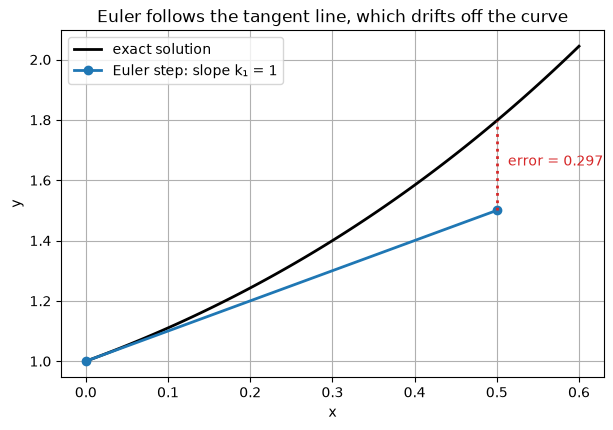

In [8]:
# Geometric picture: one large Euler step (h = 0.5) so the gap is visible
h = 0.5
xf = np.linspace(0, 0.6, 100)
plt.plot(xf, exact(xf), "k", lw=2, label="exact solution")
k1 = f(0, 1)
plt.plot([0, h], [1, 1 + h * k1], "C0o-", lw=2, label=f"Euler step: slope k₁ = {k1:g}")
plt.vlines(h, 1 + h * k1, exact(h), colors="C3", linestyles=":", lw=2)
plt.annotate(f"error = {exact(h) - (1 + h*k1):.3f}", (h, (1 + h*k1 + exact(h)) / 2),
             xytext=(8, 0), textcoords="offset points", color="C3")
plt.title("Euler follows the tangent line, which drifts off the curve")
plt.xlabel("x"); plt.ylabel("y"); plt.legend();

### 6.3 Heun's method (improved Euler)

**Derivation from the trapezoidal rule.** Estimate the integral with the trapezoidal rule, which averages the slopes at both ends of the step:

$$y_{n+1} = y_n + \frac{h}{2}\Big[f(x_n, y_n) + f(x_{n+1}, y_{n+1})\Big].$$

The problem is that $y_{n+1}$ appears on both sides (the formula is **implicit**). Heun's fix is to first *predict* $y_{n+1}$ with an Euler step and then *correct* it with the trapezoidal average. That makes it a **predictor–corrector** method:

$$
\begin{aligned}
k_1 &= f(x_n, y_n) && \text{slope at the start}\\
y^{*}_{n+1} &= y_n + h k_1 && \text{predictor (an Euler step)}\\
k_2 &= f(x_{n+1}, y^{*}_{n+1}) && \text{slope at the predicted end point}\\
y_{n+1} &= y_n + \tfrac{h}{2}(k_1 + k_2) && \text{corrector: use the average slope}
\end{aligned}
$$

**Why it is better.** If the curve is concave up, the start slope $k_1$ is too small and the end slope $k_2$ is too large, so their average largely cancels the error. The local error becomes $O(h^3)$ and the global error $O(h^2)$, so Heun is **order 2**. Halving $h$ divides the error by about 4. Each step costs **2** evaluations of $f$.

In [9]:
def heun(f, x0, y0, h, n):
    x, y = np.zeros(n + 1), np.zeros(n + 1)
    x[0], y[0] = x0, y0
    for i in range(n):
        k1 = f(x[i], y[i])
        k2 = f(x[i] + h, y[i] + h * k1)
        y[i + 1] = y[i] + h / 2 * (k1 + k2)
        x[i + 1] = x[i] + h
    return x, y

#### Worked example: Heun by hand, $h = 0.1$

| $n$ | $x_n$ | $y_n$ | $k_1 = x_n + y_n$ | $y^{*} = y_n + 0.1k_1$ | $k_2 = x_{n+1} + y^{*}$ | $y_{n+1} = y_n + 0.05(k_1 + k_2)$ | error |
|---|---|---|---|---|---|---|---|
| 0 | 0.0 | 1.000000 | 1.000000 | 1.100000 | 1.200000 | 1.110000 | 0.00034 |
| 1 | 0.1 | 1.110000 | 1.210000 | 1.231000 | 1.431000 | 1.242050 | 0.00076 |
| 2 | 0.2 | 1.242050 | 1.442050 | 1.386255 | 1.686255 | 1.398465 | 0.00125 |

After three steps the error is $0.00125$, about **30 times smaller** than Euler's $0.0377$, for twice the work.

### 6.4 The classical Runge–Kutta method (RK4)

**Derivation from Simpson's rule.** Simpson's rule weights the midpoint four times as heavily as the ends:

$$\int_{x_n}^{x_{n+1}} f\,dx \approx \frac{h}{6}\Big[f_{\text{start}} + 4 f_{\text{mid}} + f_{\text{end}}\Big].$$

RK4 estimates the midpoint slope **twice**, each time more accurately than the last, and splits the weight $4$ into $2 + 2$:

$$
\begin{aligned}
k_1 &= f(x_n,\ y_n) && \text{slope at the start}\\
k_2 &= f\!\left(x_n + \tfrac{h}{2},\ y_n + \tfrac{h}{2}k_1\right) && \text{slope at the midpoint, reached using } k_1\\
k_3 &= f\!\left(x_n + \tfrac{h}{2},\ y_n + \tfrac{h}{2}k_2\right) && \text{slope at the midpoint, reached using the better } k_2\\
k_4 &= f\!\left(x_n + h,\ y_n + h k_3\right) && \text{slope at the end, reached using } k_3\\[4pt]
y_{n+1} &= y_n + \tfrac{h}{6}\big(k_1 + 2k_2 + 2k_3 + k_4\big)
\end{aligned}
$$

The weights $\tfrac{1}{6}, \tfrac{2}{6}, \tfrac{2}{6}, \tfrac{1}{6}$ add up to 1, so $\tfrac{1}{6}(k_1 + 2k_2 + 2k_3 + k_4)$ is a weighted *average slope*. The local error is $O(h^5)$ and the global error $O(h^4)$: RK4 is **order 4**, and halving $h$ divides the error by about 16. Each step costs **4** evaluations of $f$.

In [10]:
def rk4(f, x0, y0, h, n):
    x, y = np.zeros(n + 1), np.zeros(n + 1)
    x[0], y[0] = x0, y0
    for i in range(n):
        k1 = f(x[i], y[i])
        k2 = f(x[i] + h / 2, y[i] + h / 2 * k1)
        k3 = f(x[i] + h / 2, y[i] + h / 2 * k2)
        k4 = f(x[i] + h, y[i] + h * k3)
        y[i + 1] = y[i] + h / 6 * (k1 + 2 * k2 + 2 * k3 + k4)
        x[i + 1] = x[i] + h
    return x, y

#### Worked example: RK4 by hand, first step with $h = 0.1$

| stage | evaluation point $(x, y)$ | slope |
|---|---|---|
| $k_1$ | $(0,\ 1)$ | $1$ |
| $k_2$ | $(0.05,\ 1 + 0.05 \cdot 1) = (0.05,\ 1.05)$ | $1.1$ |
| $k_3$ | $(0.05,\ 1 + 0.05 \cdot 1.1) = (0.05,\ 1.055)$ | $1.105$ |
| $k_4$ | $(0.1,\ 1 + 0.1 \cdot 1.105) = (0.1,\ 1.1105)$ | $1.2105$ |

$$y_1 = 1 + \frac{0.1}{6}\big(1 + 2(1.1) + 2(1.105) + 1.2105\big) = 1 + \frac{0.1}{6}(6.6205) = 1.1103417.$$

Exact: $y(0.1) = 1.1103418$. The error is $1.7 \times 10^{-7}$, about 60,000 times smaller than Euler's first step.

### 6.5 Seeing the slopes

Below, one large step ($h = 0.5$) from $(0, 1)$ shows where each method samples the slope. Short arrows mark each sampled slope; the coloured line is the step actually taken.

exact y(0.5) = 1.797443


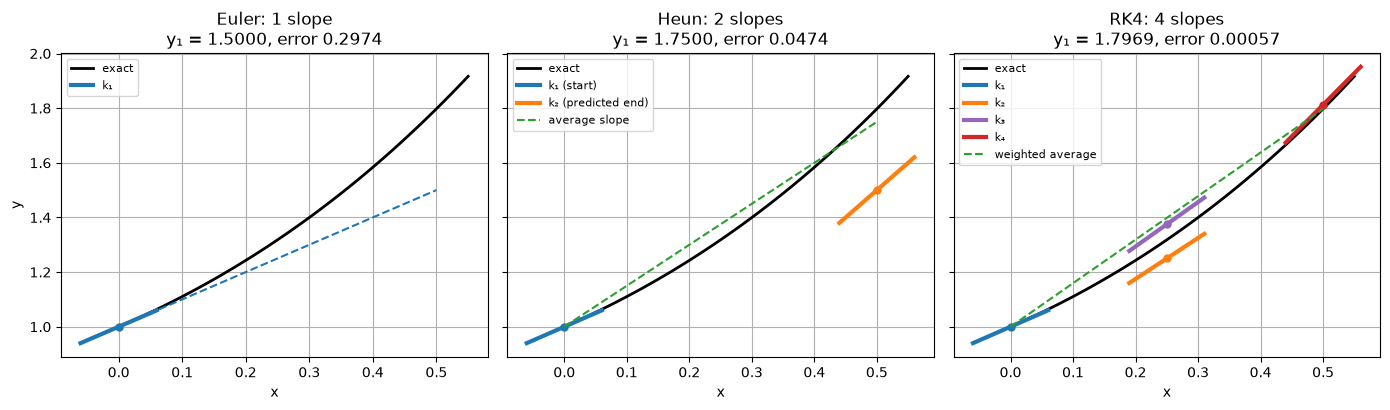

In [11]:
h, x0, y0 = 0.5, 0.0, 1.0
xf = np.linspace(0, 0.55, 100)

def slope_mark(ax, x, y, s, color, label=None):
    d = 0.06
    ax.plot([x - d, x + d], [y - d * s, y + d * s], color=color, lw=3, label=label)
    ax.plot(x, y, "o", color=color, ms=5)

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), sharey=True)
for ax in axes:
    ax.plot(xf, exact(xf), "k", lw=2, label="exact")
    ax.set_xlabel("x")
axes[0].set_ylabel("y")

# Euler
k1 = f(x0, y0)
y_e = y0 + h * k1
slope_mark(axes[0], x0, y0, k1, "C0", "k₁")
axes[0].plot([x0, h], [y0, y_e], "C0--")
axes[0].set_title(f"Euler: 1 slope\ny₁ = {y_e:.4f}, error {exact(h) - y_e:.4f}")

# Heun
k2 = f(x0 + h, y0 + h * k1)
y_h = y0 + h / 2 * (k1 + k2)
slope_mark(axes[1], x0, y0, k1, "C0", "k₁ (start)")
slope_mark(axes[1], x0 + h, y0 + h * k1, k2, "C1", "k₂ (predicted end)")
axes[1].plot([x0, h], [y0, y_h], "C2--", label="average slope")
axes[1].set_title(f"Heun: 2 slopes\ny₁ = {y_h:.4f}, error {exact(h) - y_h:.4f}")

# RK4
r1 = f(x0, y0)
r2 = f(x0 + h / 2, y0 + h / 2 * r1)
r3 = f(x0 + h / 2, y0 + h / 2 * r2)
r4 = f(x0 + h, y0 + h * r3)
y_r = y0 + h / 6 * (r1 + 2 * r2 + 2 * r3 + r4)
slope_mark(axes[2], x0, y0, r1, "C0", "k₁")
slope_mark(axes[2], x0 + h / 2, y0 + h / 2 * r1, r2, "C1", "k₂")
slope_mark(axes[2], x0 + h / 2, y0 + h / 2 * r2, r3, "C4", "k₃")
slope_mark(axes[2], x0 + h, y0 + h * r3, r4, "C3", "k₄")
axes[2].plot([x0, h], [y0, y_r], "C2--", label="weighted average")
axes[2].set_title(f"RK4: 4 slopes\ny₁ = {y_r:.4f}, error {exact(h) - y_r:.5f}")

for ax in axes:
    ax.legend(loc="upper left", fontsize=8)
plt.tight_layout()
print(f"exact y(0.5) = {exact(h):.6f}")

### 6.6 Why the order is what it is: matching the Taylor series

For the test problem, the exact solution after one step from $(0, 1)$ has the Taylor series

$$y(h) = 2e^{h} - h - 1 = 1 + h + h^2 + \frac{h^3}{3} + \frac{h^4}{12} + \frac{h^5}{60} + \cdots$$

Expanding each method's formula for one step, symbolically in $h$:

| Method | One step gives | First term missed (local error) | Predicted at $h=0.1$ | Actual |
|---|---|---|---|---|
| Euler | $1 + h$ | $h^2$ | $1.0 \times 10^{-2}$ | $1.03 \times 10^{-2}$ |
| Heun | $1 + h + h^2$ | $h^3/3$ | $3.3 \times 10^{-4}$ | $3.42 \times 10^{-4}$ |
| RK4 | $1 + h + h^2 + \frac{h^3}{3} + \frac{h^4}{12}$ | $h^5/60$ | $1.7 \times 10^{-7}$ | $1.69 \times 10^{-7}$ |

*(For RK4: $k_1 = 1$, $k_2 = 1 + h$, $k_3 = 1 + h + \tfrac{h^2}{2}$, $k_4 = 1 + 2h + h^2 + \tfrac{h^3}{2}$; substituting gives the expression in the table.)*

This is the real meaning of order: **a method of order $p$ reproduces the Taylor series of the true solution through the $h^p$ term.** The first term it misses, of size $h^{p+1}$, is the local error. Over $1/h$ steps these add up to a global error of $h^p$.

### 6.7 All three methods side by side

In [12]:
h, n = 0.1, 10
x, ye = euler(f, 0, 1, h, n)
_, yh = heun(f, 0, 1, h, n)
_, yr = rk4(f, 0, 1, h, n)
yx = exact(x)

print(f"{'x':>5} {'Euler':>10} {'Heun':>10} {'RK4':>12} {'Exact':>12} "
      f"{'|err| Eul':>10} {'|err| Heun':>10} {'|err| RK4':>10}")
for i in range(n + 1):
    print(f"{x[i]:5.1f} {ye[i]:10.6f} {yh[i]:10.6f} {yr[i]:12.8f} {yx[i]:12.8f} "
          f"{abs(ye[i]-yx[i]):10.2e} {abs(yh[i]-yx[i]):10.2e} {abs(yr[i]-yx[i]):10.2e}")

    x      Euler       Heun          RK4        Exact  |err| Eul |err| Heun  |err| RK4
  0.0   1.000000   1.000000   1.00000000   1.00000000   0.00e+00   0.00e+00   0.00e+00
  0.1   1.100000   1.110000   1.11034167   1.11034184   1.03e-02   3.42e-04   1.69e-07
  0.2   1.220000   1.242050   1.24280514   1.24280552   2.28e-02   7.56e-04   3.75e-07
  0.3   1.362000   1.398465   1.39971699   1.39971762   3.77e-02   1.25e-03   6.21e-07
  0.4   1.528200   1.581804   1.58364848   1.58364940   5.54e-02   1.85e-03   9.15e-07
  0.5   1.721020   1.794894   1.79744128   1.79744254   7.64e-02   2.55e-03   1.26e-06
  0.6   1.943122   2.040857   2.04423592   2.04423760   1.01e-01   3.38e-03   1.68e-06
  0.7   2.197434   2.323147   2.32750325   2.32750541   1.30e-01   4.36e-03   2.16e-06
  0.8   2.487178   2.645578   2.65107913   2.65108186   1.64e-01   5.50e-03   2.73e-06
  0.9   2.815895   3.012364   3.01920283   3.01920622   2.03e-01   6.84e-03   3.39e-06
  1.0   3.187485   3.428162   3.43655949   

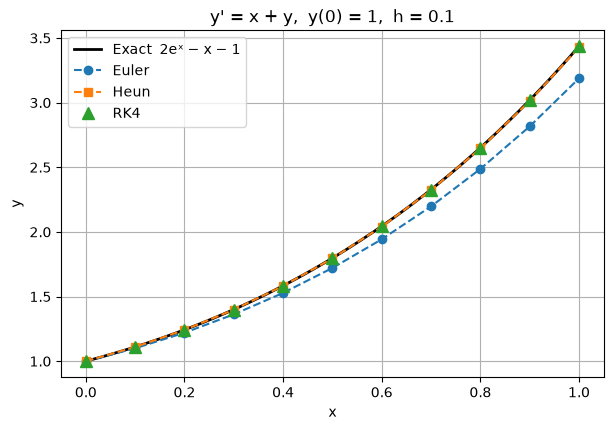

In [13]:
xf = np.linspace(0, 1, 200)
plt.plot(xf, exact(xf), "k", lw=2, label="Exact  2eˣ − x − 1")
plt.plot(x, ye, "o--", label="Euler")
plt.plot(x, yh, "s--", label="Heun")
plt.plot(x, yr, "^", ms=8, label="RK4")
plt.title("y' = x + y,  y(0) = 1,  h = 0.1")
plt.xlabel("x"); plt.ylabel("y"); plt.legend();

## 7. Error, order and efficiency

### 7.1 Measuring the order

If the global error is $E(h) \approx Ch^{p}$, then

$$\frac{E(h)}{E(h/2)} \approx 2^{p}, \qquad \log E \approx \log C + p\log h.$$

So the order can be read off in two ways: from the **error ratio** when $h$ is halved, or from the **slope of a log–log plot** of error against $h$.

| Method | Order $p$ | Error ratio when $h$ is halved |
|---|---|---|
| Euler | 1 | ≈ 2 |
| Heun | 2 | ≈ 4 |
| RK4 | 4 | ≈ 16 |

We check this for the test problem by measuring the error at $x = 1$ (exact value $2e - 2 \approx 3.436564$).

In [14]:
hs = [0.2, 0.1, 0.05, 0.025, 0.0125]
methods = {"Euler": euler, "Heun": heun, "RK4": rk4}
cost_per_step = {"Euler": 1, "Heun": 2, "RK4": 4}
errors = {name: [] for name in methods}

for h in hs:
    n = round(1 / h)
    for name, method in methods.items():
        _, y = method(f, 0, 1, h, n)
        errors[name].append(abs(y[-1] - exact(1.0)))

print(f"{'h':>8}" + "".join(f"{m:>14}{'ratio':>8}" for m in methods))
for i, h in enumerate(hs):
    row = f"{h:8.4f}"
    for name in methods:
        e = errors[name]
        ratio = f"{e[i-1] / e[i]:8.2f}" if i else f"{'':>8}"
        row += f"{e[i]:14.3e}{ratio}"
    print(row)

for name, p in zip(methods, [1, 2, 4]):
    slope = np.polyfit(np.log(hs), np.log(errors[name]), 1)[0]
    print(f"{name:6s} observed order ≈ {slope:.2f}  (theory {p})")

       h         Euler   ratio          Heun   ratio           RK4   ratio
  0.2000     4.599e-01             3.115e-02             6.138e-05        
  0.1000     2.491e-01    1.85     8.402e-03    3.71     4.169e-06   14.73
  0.0500     1.300e-01    1.92     2.182e-03    3.85     2.716e-07   15.35
  0.0250     6.644e-02    1.96     5.558e-04    3.93     1.733e-08   15.67
  0.0125     3.359e-02    1.98     1.403e-04    3.96     1.095e-09   15.83
Euler  observed order ≈ 0.95  (theory 1)
Heun   observed order ≈ 1.95  (theory 2)
RK4    observed order ≈ 3.95  (theory 4)


### 7.2 Accuracy per unit of work

Smaller steps are not free. The real cost of a method is the number of times it evaluates $f$: $N$ for Euler, $2N$ for Heun and $4N$ for RK4. A fair comparison plots the error against that cost.

Euler  needs about    2,687,502 evaluations of f for error 1e-6
Heun   needs about        1,895 evaluations of f for error 1e-6
RK4    needs about           58 evaluations of f for error 1e-6


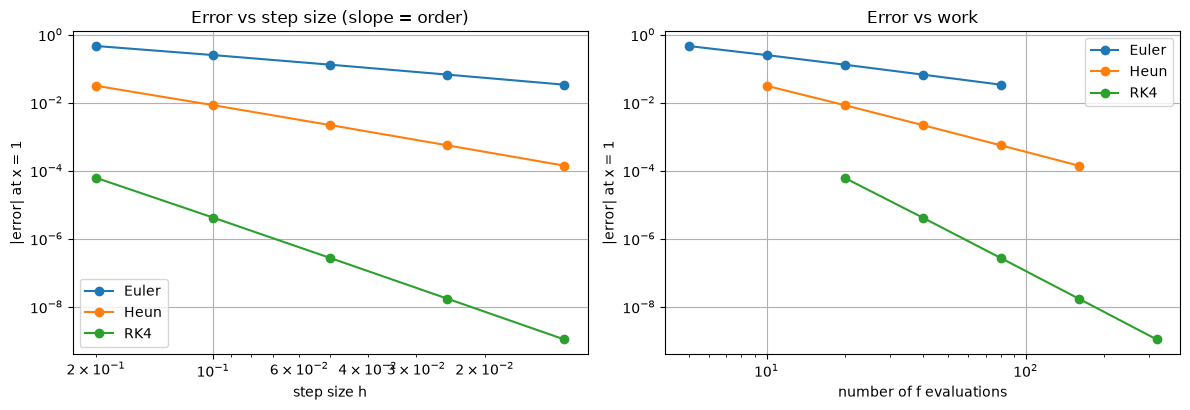

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for name in methods:
    axes[0].loglog(hs, errors[name], "o-", label=name)
    evals = [cost_per_step[name] * round(1 / h) for h in hs]
    axes[1].loglog(evals, errors[name], "o-", label=name)
axes[0].invert_xaxis()
axes[0].set_xlabel("step size h"); axes[0].set_ylabel("|error| at x = 1")
axes[0].set_title("Error vs step size (slope = order)")
axes[1].set_xlabel("number of f evaluations"); axes[1].set_ylabel("|error| at x = 1")
axes[1].set_title("Error vs work")
for ax in axes:
    ax.legend()
plt.tight_layout()

# Work needed for an error of 1e-6, using E ≈ C h^p from the finest run
for name, p in zip(methods, [1, 2, 4]):
    evals = cost_per_step[name] * round(1 / hs[-1])
    need = evals * (errors[name][-1] / 1e-6) ** (1 / p)
    print(f"{name:6s} needs about {need:12,.0f} evaluations of f for error 1e-6")

**Takeaway.** In the right-hand plot, RK4's line lies far below the others: for any fixed amount of work it is far more accurate. To reach an error of $10^{-6}$, Euler needs about 2.7 million evaluations of $f$, Heun about 1,900 and RK4 about 60. Higher-order methods win whenever the solution is smooth.

### 7.3 Estimating the error when the exact solution is unknown

In real problems there is no exact solution to compare with. **Richardson's idea:** solve twice, with step sizes $h$ and $h/2$. Since $E(h) \approx Ch^p$,

$$y(b) - y_{h/2} \approx \frac{y_{h/2} - y_{h}}{2^{p} - 1}.$$

* The right-hand side is an **error estimate** for the finer solution, computed using only numerical results.
* Adding it to $y_{h/2}$ gives an **extrapolated** value that is more accurate than either run: one order higher.

Below we check the estimate against the true error for the test problem.

In [16]:
print(f"{'method':>6} {'y_h':>12} {'y_h/2':>12} {'estimated err':>14} {'true err':>12} {'extrapolated':>13} {'its err':>10}")
for name, p in [("Euler", 1), ("Heun", 2), ("RK4", 4)]:
    method = methods[name]
    _, y1 = method(f, 0, 1, 0.1, 10)
    _, y2 = method(f, 0, 1, 0.05, 20)
    est = (y2[-1] - y1[-1]) / (2**p - 1)
    true = exact(1.0) - y2[-1]
    extrap = y2[-1] + est
    print(f"{name:>6} {y1[-1]:12.8f} {y2[-1]:12.8f} {est:14.3e} {true:12.3e} "
          f"{extrap:13.8f} {abs(exact(1.0) - extrap):10.2e}")

method          y_h        y_h/2  estimated err     true err  extrapolated    its err
 Euler   3.18748492   3.30659541      1.191e-01    1.300e-01    3.42570590   1.09e-02
  Heun   3.42816169   3.43438211      2.073e-03    2.182e-03    3.43645558   1.08e-04
   RK4   3.43655949   3.43656339      2.598e-07    2.716e-07    3.43656365   1.18e-08


The estimated errors closely match the true errors, so the computed solutions **tell you how accurate they are**. Extrapolation also helps: the extrapolated Euler value is about 12 times more accurate than the finer Euler run, and the extrapolated RK4 value is accurate to about $10^{-8}$. This is the standard check in practice: **always re-run with half the step size and compare.**

## 8. Stability: when a small error explodes

Accuracy is not the only concern. A method can also be **unstable**: for a step that is too large, errors are amplified at every step and the numerical solution blows up, even though the true solution decays.

### 8.1 The test equation

Take $y' = -\lambda y$ with $\lambda > 0$, $y(0) = 1$. The exact solution $y = e^{-\lambda x}$ decays to 0. Euler gives

$$y_{n+1} = y_n - h\lambda y_n = (1 - h\lambda)\,y_n \quad\Longrightarrow\quad y_n = (1 - h\lambda)^{n}.$$

$R = 1 - h\lambda$ is the **amplification factor**. The numerical solution decays only if $|R| < 1$, that is

$$\boxed{h < \frac{2}{\lambda}} \quad\text{(Euler's stability limit).}$$

With $\lambda = 20$ the limit is $h < 0.1$:

| $h$ | $R = 1 - 20h$ | behaviour |
|---|---|---|
| 0.02 | 0.6 | smooth decay, like the exact solution |
| 0.08 | −0.6 | decays, but flips sign every step |
| 0.12 | −1.4 | oscillates and grows without bound |

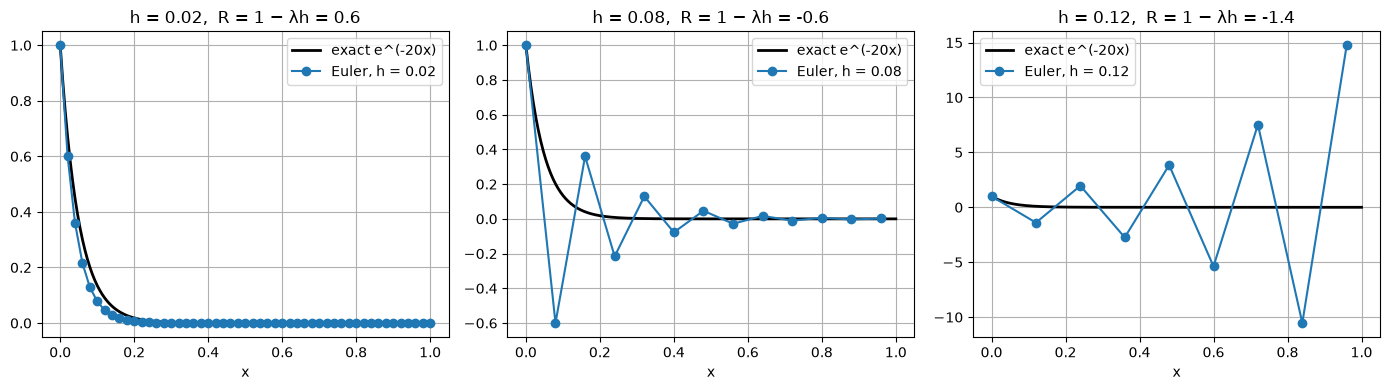

In [17]:
lam = 20.0
decay = lambda x, y: -lam * y
xf = np.linspace(0, 1, 300)

fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=False)
for ax, h in zip(axes, [0.02, 0.08, 0.12]):
    n = round(1 / h)
    x, y = euler(decay, 0, 1, h, n)
    ax.plot(xf, np.exp(-lam * xf), "k", lw=2, label="exact e^(-20x)")
    ax.plot(x, y, "o-", label=f"Euler, h = {h}")
    ax.set_title(f"h = {h},  R = 1 − λh = {1 - lam*h:.1f}")
    ax.set_xlabel("x"); ax.legend()
plt.tight_layout()

### 8.2 Implicit methods and stiff equations

**Backward (implicit) Euler** uses the slope at the *end* of the step:

$$y_{n+1} = y_n + h\,f(x_{n+1}, y_{n+1}).$$

For the test equation this gives $y_{n+1} = y_n - h\lambda y_{n+1}$, so

$$y_{n+1} = \frac{y_n}{1 + h\lambda}, \qquad |R| = \frac{1}{1 + h\lambda} < 1 \text{ for every } h > 0.$$

It is **unconditionally stable**. The price is that, in general, each step requires *solving* an equation for $y_{n+1}$, usually with Newton's method.

An equation is called **stiff** when stability, not accuracy, forces explicit methods to take tiny steps. This typically happens when the solution has a very fast-decaying part alongside a slow part. Explicit methods (Euler, Heun, RK4) all have a stability limit of the form $h < c/\lambda$; for RK4 it is $c \approx 2.79$. For stiff problems, implicit methods are much cheaper overall.

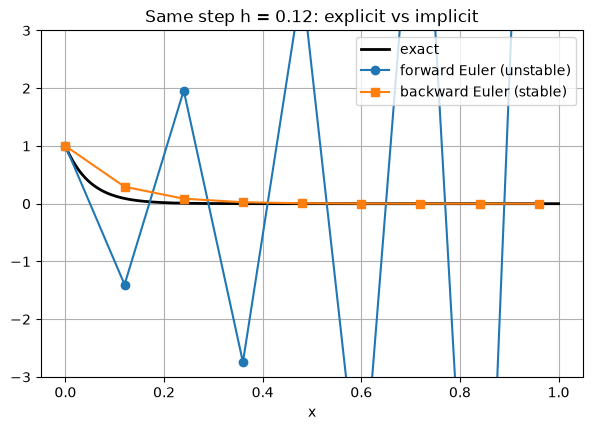

In [18]:
def backward_euler_linear(lam, y0, h, n):
    # Backward Euler for y' = -lam * y (the implicit equation solves in closed form)
    x = np.arange(n + 1) * h
    y = y0 / (1 + h * lam) ** np.arange(n + 1)
    return x, y

h = 0.12
x, y_fwd = euler(decay, 0, 1, h, round(1 / h))
_, y_bwd = backward_euler_linear(lam, 1, h, round(1 / h))
plt.plot(xf, np.exp(-lam * xf), "k", lw=2, label="exact")
plt.plot(x, y_fwd, "o-", label="forward Euler (unstable)")
plt.plot(x, y_bwd, "s-", label="backward Euler (stable)")
plt.ylim(-3, 3)
plt.title(f"Same step h = {h}: explicit vs implicit")
plt.xlabel("x"); plt.legend();

## 9. Numerical methods in practice

### 9.1 Adaptive step size

A fixed $h$ wastes effort where the solution is smooth and is too coarse where it changes quickly. **Adaptive** solvers choose $h$ step by step:

1. Take a step with two methods of different order, e.g. Euler (order 1) and Heun (order 2), which share $k_1$.
2. Their difference estimates the local error: $\text{err} \approx |y_{\text{Heun}} - y_{\text{Euler}}| = \tfrac{h}{2}|k_2 - k_1|$.
3. If $\text{err} \le \text{tol}\,(1 + |y|)$ (a mixed absolute/relative tolerance), accept the step; otherwise reject it and retry with a smaller $h$.
4. Choose the next step as $h_{\text{new}} = 0.9\,h\sqrt{\text{allowed}/\text{err}}$ (the square root because the local error of the lower-order method is $O(h^2)$).

Professional solvers use the same idea with higher-order pairs: **RK45 (Dormand–Prince)** in `scipy.integrate.solve_ivp`, MATLAB's `ode45`, or `Tsit5` in Julia's DifferentialEquations.jl.

**Example.** $y' = 1 + y^2$, $y(0) = 0$, with exact solution $y = \tan x$, which becomes very steep near $x = \pi/2 \approx 1.571$. We integrate to $x = 1.5$.

accepted steps: 89,  rejected: 3
exact tan(1.5) = 14.10142
adaptive Heun:              y(1.5) = 14.09386   error = 0.0076
fixed-step Heun, 89 steps: y(1.5) = 13.81361   error = 0.2878


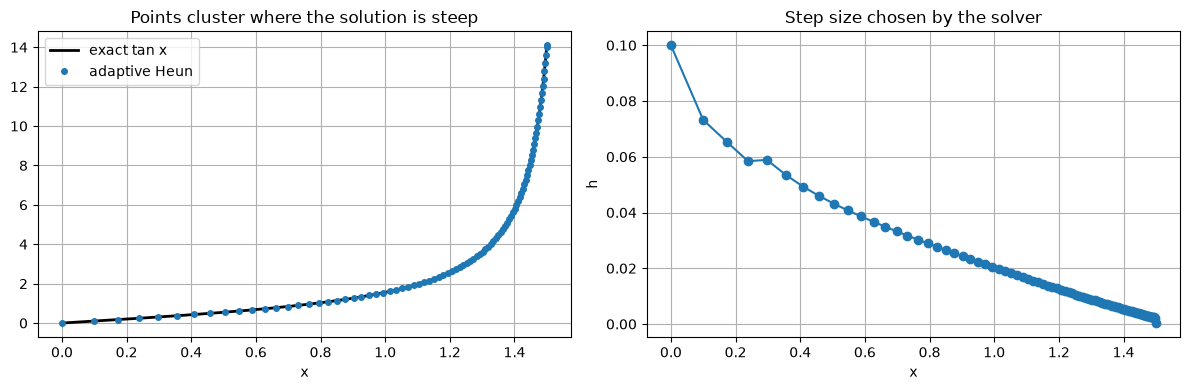

In [19]:
def adaptive_heun(f, x0, y0, x_end, tol=1e-3, h=0.1):
    xs, ys = [x0], [y0]
    x, y = x0, y0
    rejected = 0
    while x_end - x > 1e-12:
        h = min(h, x_end - x)
        k1 = f(x, y)
        k2 = f(x + h, y + h * k1)
        err = h / 2 * abs(k2 - k1)
        allowed = tol * (1 + abs(y))
        if err <= allowed:
            x, y = x + h, y + h / 2 * (k1 + k2)
            xs.append(x); ys.append(y)
        else:
            rejected += 1
        h *= min(2.0, max(0.2, 0.9 * np.sqrt(allowed / err))) if err > 0 else 2.0
    return np.array(xs), np.array(ys), rejected

tanf = lambda x, y: 1 + y**2
xa, ya, rej = adaptive_heun(tanf, 0.0, 0.0, 1.5)
print(f"accepted steps: {len(xa) - 1},  rejected: {rej}")
print(f"exact tan(1.5) = {np.tan(1.5):.5f}")
print(f"adaptive Heun:              y(1.5) = {ya[-1]:.5f}   error = {abs(ya[-1] - np.tan(1.5)):.4f}")

n_fixed = len(xa) - 1
xh, yh_fixed = heun(tanf, 0, 0, 1.5 / n_fixed, n_fixed)
print(f"fixed-step Heun, {n_fixed} steps: y(1.5) = {yh_fixed[-1]:.5f}   error = {abs(yh_fixed[-1] - np.tan(1.5)):.4f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
xf = np.linspace(0, 1.5, 300)
axes[0].plot(xf, np.tan(xf), "k", lw=2, label="exact tan x")
axes[0].plot(xa, ya, "o", ms=4, label="adaptive Heun")
axes[0].set_title("Points cluster where the solution is steep")
axes[0].set_xlabel("x"); axes[0].legend()
axes[1].plot(xa[:-1], np.diff(xa), "o-")
axes[1].set_title("Step size chosen by the solver")
axes[1].set_xlabel("x"); axes[1].set_ylabel("h")
plt.tight_layout()

With the same number of steps, the adaptive solver is about 40 times more accurate than fixed steps. It takes large steps where $\tan x$ is flat and puts its effort near $x = 1.5$, where the solution is steep.

### 9.2 Choosing a method

| Situation | Good choice |
|---|---|
| Learning, or a quick rough look | Euler |
| Smooth, non-stiff problem | RK4 with a fixed step, or adaptive RK45 |
| Solution changes scale a lot | Adaptive step size (RK45, Tsit5) |
| Stiff problem (fast and slow scales) | Implicit method: backward Euler, BDF, Rosenbrock |

### 9.3 Common pitfalls

* **Step too large:** inaccurate, or unstable (Section 8).
* **Step too small:** wasted work, and eventually **round-off error** grows. Each step adds a tiny rounding error of about $10^{-16}$, and millions of steps add those up.
* **No convergence check:** a single run tells you nothing about its accuracy. Halve $h$, or tighten the tolerance, and compare (Section 7.3).
* **Singularities and blow-up:** if the true solution becomes infinite, as $\tan x$ does at $\pi/2$, no method can step past it; adaptive solvers will shrink $h$ towards zero.
* **Order assumes smoothness:** if $f$ has a jump or a kink, the observed order drops. Place a grid point at the discontinuity.

## 10. Applications

### 10.1 Newton's law of cooling

The rate of temperature change is proportional to the difference from the surroundings:

$$\frac{dT}{dt} = -k\,(T - T_a).$$

**Problem.** A cup of coffee at $90^\circ$C is placed in a $20^\circ$C room with $k = 0.1\ \text{min}^{-1}$.
(a) What is its temperature after 10 minutes? (b) When does it reach $30^\circ$C?

The equation is separable (and linear): $T(t) = T_a + (T_0 - T_a)e^{-kt} = 20 + 70e^{-0.1t}$.

(a) $T(10) = 20 + 70e^{-1} \approx 20 + 25.752 = 45.75^\circ$C.

(b) $20 + 70e^{-0.1t} = 30 \Rightarrow e^{-0.1t} = 1/7 \Rightarrow t = 10\ln 7 \approx 19.46$ min.

T(10) exact = 45.7516   RK4 = 45.7516   Euler = 44.4075
time to reach 30 °C = 10 ln 7 = 19.4591 min


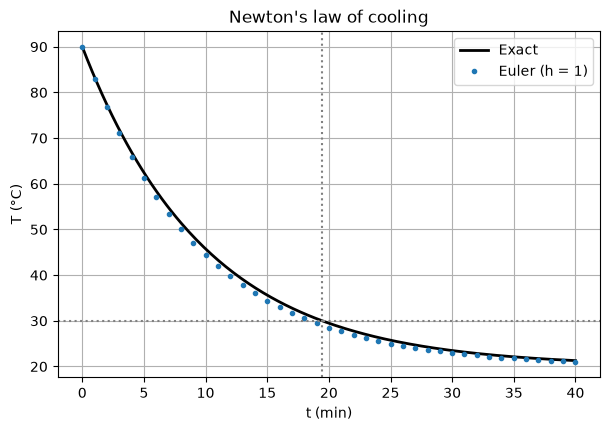

In [20]:
k, Ta, T0 = 0.1, 20.0, 90.0
cool = lambda t, T: -k * (T - Ta)
T_exact = lambda t: Ta + (T0 - Ta) * np.exp(-k * t)

t, T_rk = rk4(cool, 0, T0, 1.0, 40)       # h = 1 minute
_, T_eu = euler(cool, 0, T0, 1.0, 40)

print(f"T(10) exact = {T_exact(10):.4f}   RK4 = {T_rk[10]:.4f}   Euler = {T_eu[10]:.4f}")
print(f"time to reach 30 °C = 10 ln 7 = {10 * np.log(7):.4f} min")

tf = np.linspace(0, 40, 200)
plt.plot(tf, T_exact(tf), "k", lw=2, label="Exact")
plt.plot(t, T_eu, ".", label="Euler (h = 1)")
plt.axhline(30, color="gray", ls=":"); plt.axvline(10 * np.log(7), color="gray", ls=":")
plt.xlabel("t (min)"); plt.ylabel("T (°C)"); plt.title("Newton's law of cooling")
plt.legend();

### 10.2 Logistic population growth

$$\frac{dP}{dt} = rP\left(1 - \frac{P}{K}\right),$$

where $r$ is the growth rate and $K$ is the carrying capacity. Separating variables with partial fractions gives

$$P(t) = \frac{K}{1 + \left(\dfrac{K - P_0}{P_0}\right)e^{-rt}}.$$

**Problem.** $r = 0.5$ per year, $K = 1000$, $P_0 = 100$. Find $P(5)$.

$$P(5) = \frac{1000}{1 + 9e^{-2.5}} = \frac{1000}{1 + 9(0.082085)} = \frac{1000}{1.738765} \approx 575.1.$$

The equilibria are $P = 0$ (unstable) and $P = K$ (stable). Growth is fastest at $P = K/2$.

P(5) exact = 575.1209   RK4 (h=0.5) = 575.1165


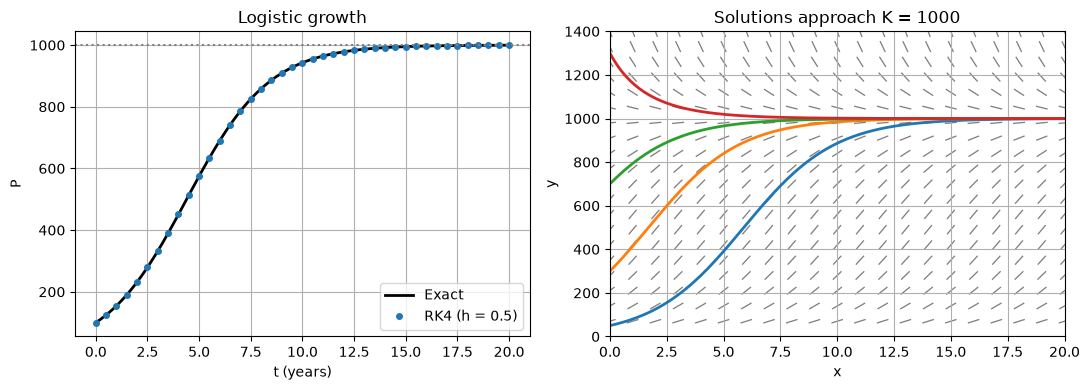

In [21]:
r, K, P0 = 0.5, 1000.0, 100.0
logistic = lambda t, P: r * P * (1 - P / K)
P_exact = lambda t: K / (1 + (K - P0) / P0 * np.exp(-r * t))

t, P_rk = rk4(logistic, 0, P0, 0.5, 40)
print(f"P(5) exact = {P_exact(5):.4f}   RK4 (h=0.5) = {P_rk[10]:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
tf = np.linspace(0, 20, 200)
axes[0].plot(tf, P_exact(tf), "k", lw=2, label="Exact")
axes[0].plot(t, P_rk, "o", ms=4, label="RK4 (h = 0.5)")
axes[0].axhline(K, color="gray", ls=":"); axes[0].set_title("Logistic growth")
axes[0].set_xlabel("t (years)"); axes[0].set_ylabel("P"); axes[0].legend()

direction_field(logistic, (0, 20), (0, 1400), ax=axes[1])
for p0 in [50, 300, 700, 1300]:
    _, Pp = rk4(logistic, 0, p0, 0.1, 200)
    axes[1].plot(np.linspace(0, 20, 201), Pp, lw=2)
axes[1].set_title("Solutions approach K = 1000")
plt.tight_layout()

## 11. An equation with no elementary solution

The Riccati equation

$$y' = x^2 + y^2, \qquad y(0) = 0$$

cannot be solved in terms of elementary functions. We estimate $y(1)$ with RK4 and check the result by repeatedly halving $h$. When the digits stop changing, the answer has converged.

In [22]:
g = lambda x, y: x**2 + y**2

prev = None
print(f"{'h':>8} {'y(1) RK4':>16} {'change':>12}")
for h in [0.2, 0.1, 0.05, 0.025, 0.0125]:
    _, y = rk4(g, 0, 0, h, round(1 / h))
    change = f"{abs(y[-1] - prev):12.2e}" if prev is not None else ""
    print(f"{h:8.4f} {y[-1]:16.10f} {change}")
    prev = y[-1]

       h         y(1) RK4       change
  0.2000     0.3502575491 
  0.1000     0.3502337418     2.38e-05
  0.0500     0.3502319725     1.77e-06
  0.0250     0.3502318526     1.20e-07
  0.0125     0.3502318448     7.79e-09


The last two values agree to about 8 significant figures: $y(1) \approx 0.3502318$. The solution grows quickly afterwards and blows up near $x \approx 2.003$, a reminder that solutions of nonlinear ODEs can exist only on a finite interval.

## 12. Summary

| Type | Form | Method |
|---|---|---|
| Separable | $y' = g(x)h(y)$ | $\int dy/h = \int g\,dx$ |
| Linear | $y' + P y = Q$ | Integrating factor $\mu = e^{\int P}$ |
| Exact | $M\,dx + N\,dy = 0$, $M_y = N_x$ | Find $F$ with $F_x = M$, $F_y = N$; then $F = C$ |
| Anything else | $y' = f(x,y)$ | Numerical: Euler (order 1), Heun (2), RK4 (4) |

## 13. Exercises

1. Solve $y' = y\cos x$, $y(0) = 2$.
2. Solve $y' - 3y = e^{2x}$, $y(0) = 0$.
3. Show that $(y e^{x} + 2x)\,dx + (e^{x} - 1)\,dy = 0$ is exact and solve it with $y(1) = 0$.
4. Use Euler with $h = 0.25$ to estimate $y(1)$ for $y' = -2xy$, $y(0) = 1$. Compare with the exact value $e^{-1}$.
5. Repeat Exercise 4 with RK4 and $h = 0.25$. How many times smaller is the error?

**Answers**

1. $y = 2e^{\sin x}$
2. $y = e^{3x} - e^{2x}$
3. $M_y = e^{x} = N_x$; $F = ye^{x} + x^2 - y$, so $ye^{x} + x^2 - y = 1$, giving $y = \dfrac{1 - x^2}{e^{x} - 1}$.
4. and 5. Run the cell below.

In [23]:
q = lambda x, y: -2 * x * y
_, y_eu = euler(q, 0, 1, 0.25, 4)
_, y_rk = rk4(q, 0, 1, 0.25, 4)
ex = np.exp(-1)
print(f"Exact  y(1) = {ex:.6f}")
print(f"Euler  y(1) = {y_eu[-1]:.6f}   error = {abs(y_eu[-1] - ex):.2e}")
print(f"RK4    y(1) = {y_rk[-1]:.6f}   error = {abs(y_rk[-1] - ex):.2e}")
print(f"Error ratio Euler / RK4 ≈ {abs(y_eu[-1] - ex) / abs(y_rk[-1] - ex):.0f}")

Exact  y(1) = 0.367879
Euler  y(1) = 0.410156   error = 4.23e-02
RK4    y(1) = 0.367934   error = 5.51e-05
Error ratio Euler / RK4 ≈ 768
